## Problem set 4

## Name: Ahmed Hanzala

## Link to your PS4 github repo: 

## Problem 0

-2 points for every missing green OK sign. 

Make sure you are in the DATA1030 environment.

In [2]:
from __future__ import print_function
from packaging.version import parse as Version
from platform import python_version

OK = '\x1b[42m[ OK ]\x1b[0m'
FAIL = "\x1b[41m[FAIL]\x1b[0m"

try:
    import importlib
except ImportError:
    print(FAIL, "Python version 3.14.6 is required,"
                " but %s is installed." % sys.version)

def import_version(pkg, min_ver, fail_msg=""):
    mod = None
    try:
        mod = importlib.import_module(pkg)
        if pkg in {'PIL'}:
            ver = mod.VERSION
        else:
            ver = mod.__version__
        if Version(ver) == Version(min_ver):
            print(OK, "%s version %s is installed."
                  % (lib, min_ver))
        else:
            print(FAIL, "%s version %s is required, but %s installed."
                  % (lib, min_ver, ver))    
    except ImportError:
        print(FAIL, '%s not installed. %s' % (pkg, fail_msg))
    return mod


# first check the python version
pyversion = Version(python_version())

if pyversion >= Version("3.14.6"):
    print(OK, "Python version is %s" % pyversion)
elif pyversion < Version("3.14.6"):
    print(FAIL, "Python version 3.14.6 is required,"
                " but %s is installed." % pyversion)
else:
    print(FAIL, "Unknown Python version: %s" % pyversion)

    
print()
requirements = {'numpy': "2.4.6", 'matplotlib': "3.11.0",'sklearn': "1.9.0", 
                'pandas': "3.0.3",'xgboost': "3.2.0", 'shap': "0.52.0", 
                'polars': "1.41.2", 'seaborn': "0.13.2", 'tabpfn': "8.0.8"}

# now the dependencies
for lib, required_version in list(requirements.items()):
    import_version(lib, required_version)

[ OK ] Python version is 3.14.6

[ OK ] numpy version 2.4.6 is installed.
[ OK ] matplotlib version 3.11.0 is installed.
[ OK ] sklearn version 1.9.0 is installed.
[ OK ] pandas version 3.0.3 is installed.
[ OK ] xgboost version 3.2.0 is installed.
[ OK ] shap version 0.52.0 is installed.
[ OK ] polars version 1.41.2 is installed.
[ OK ] seaborn version 0.13.2 is installed.
[ OK ] tabpfn version 8.0.8 is installed.


## Problem 1

We will work with the recidivism dataset in the problem set. The dataset contains information on criminal offenders screened in Florida from 2013 to 2014. The target variable (`two_year_recid`) for this dataset indicates whether or not an individual committed another crime after being released from prision. The csv file and a description are available in the `data` folder.

You can read more about the topic [here](https://www.propublica.org/article/machine-bias-risk-assessments-in-criminal-sentencing) and [here](https://arxiv.org/pdf/2106.05498.pdf). We will work with this dataset again in the context of algorithmic bias towards the end of the term.

You will read in the dataset, prepare the feature matrix and the target variable, perform EDA, and split the dataset into 60% training, 20% validation, and 20% test sets. Follow the steps outlined below.


### Problem 1a (5 points)

**q0:** Import the necessary packages. Feel free to use pandas or polars, matplotlib, and sklearn.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer

**q1:** Read in the dataset.

In [4]:
df = pd.read_csv('data/recidivism_data.csv')
df.head()

,id,name,sex,age,age_cat,race,juv_fel_count,juv_misd_count,juv_other_count,priors_count,c_charge_degree,r_days_from_arrest,two_year_recid,c_jail_days,custody_days
0,1,miguel hernandez,Male,69,Greater than 45,Other,0,0,0,0,F,NaN,0,0.984468,7.0
1,3,kevon dixon,Male,34,25 - 45,African-American,0,0,0,0,F,NaN,1,10.077384,10.0
2,4,ed philo,Male,24,Less than 25,African-American,0,0,1,4,F,0.0,1,1.085764,0.0
3,5,marcu brown,Male,23,Less than 25,African-American,0,1,0,1,F,NaN,0,NaN,NaN
4,6,bouthy pierrelouis,Male,43,25 - 45,Other,0,0,0,2,F,NaN,0,NaN,NaN


**q2:** Drop the `id` and `name` columns because those are not useful for a machine learning algorithm.

In [5]:
df = df.drop(columns=['id', 'name'])

**q3:** Prepare the feature matrix `X` and the target variable `y`.

In [6]:
y = df['two_year_recid']
X = df.drop(columns=['two_year_recid'])

### Problem 1b (5 points)

Answer the following EDA-related questions.

**q0:** Display the columns of the data frame.

In [7]:
print(df.columns)

Index(['sex', 'age', 'age_cat', 'race', 'juv_fel_count', 'juv_misd_count',
       'juv_other_count', 'priors_count', 'c_charge_degree',
       'r_days_from_arrest', 'two_year_recid', 'c_jail_days', 'custody_days'],
      dtype='str')


**q1:** How many rows and columns do we have in the dataframe?

In [8]:
print(df.shape)

(7214, 13)


**q2:** What are the data types of the columns? Make sure that the output is not truncated and you see the type of each column.

In [9]:
pd.set_option('display.max_rows', None)
print(df.dtypes)

sex                       str
age                     int64
age_cat                   str
race                      str
juv_fel_count           int64
juv_misd_count          int64
juv_other_count         int64
priors_count            int64
c_charge_degree           str
r_days_from_arrest    float64
two_year_recid          int64
c_jail_days           float64
custody_days          float64
dtype: object


**q3:** The ML target variable in this dataset is two year recidivism. We will develop ML pipelines to predict this variable based on the other features.

Is this column continuous or categorical? Please use .describe or .value_counts to take a quick look at this feature.

In [10]:
print(df['two_year_recid'].value_counts())

two_year_recid
0    3963
1    3251
Name: count, dtype: int64


**q4:** Visualize the target variable. Don't forget the axis labels and graph title. Make sure to use appropriate arguments to best display the data.

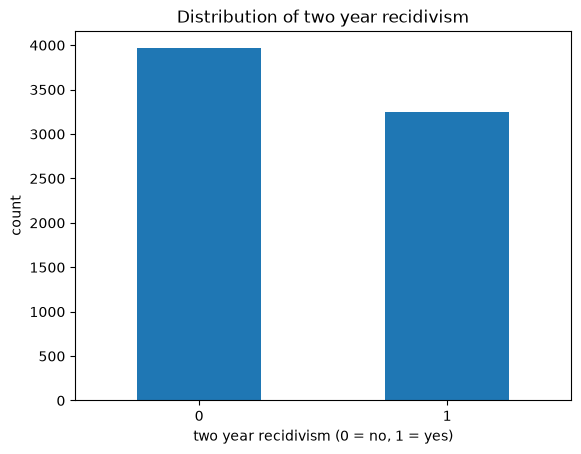

In [11]:
df['two_year_recid'].value_counts().sort_index().plot.bar(rot=0)
plt.xlabel('two year recidivism (0 = no, 1 = yes)')
plt.ylabel('count')
plt.title('Distribution of two year recidivism')
plt.show()

### Problem 1c (10 points)

**q0:** Visualize each feature (12 figures total). Make sure to add axis labels, units if necessary, and a figure title.

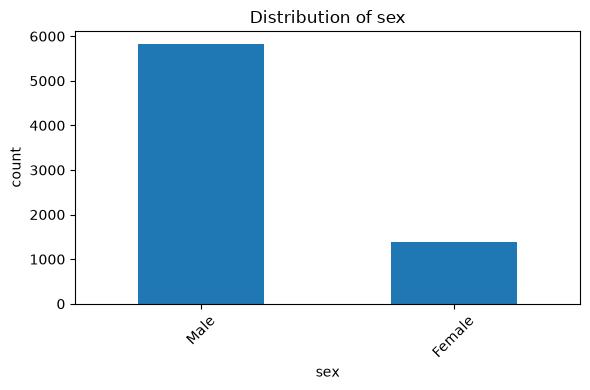

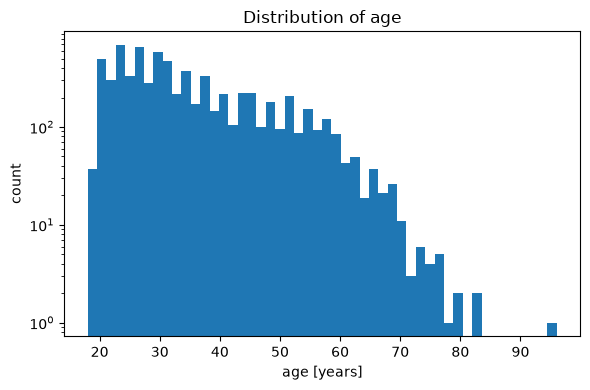

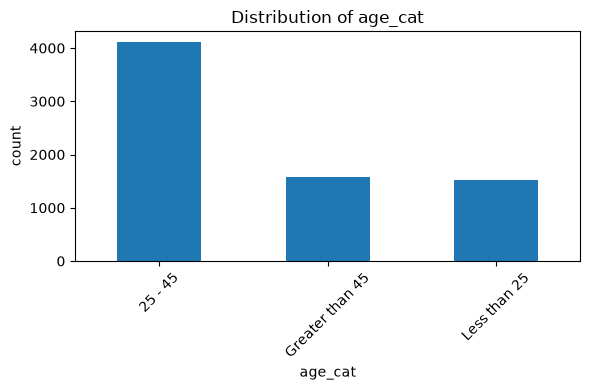

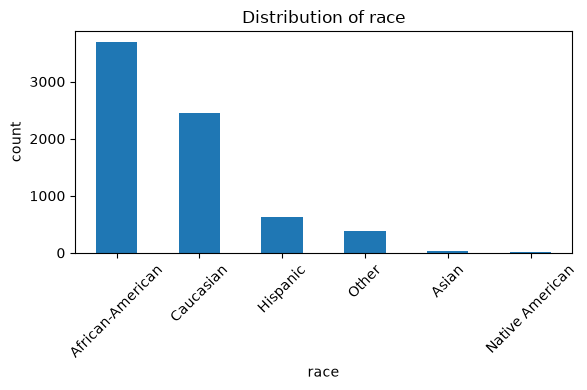

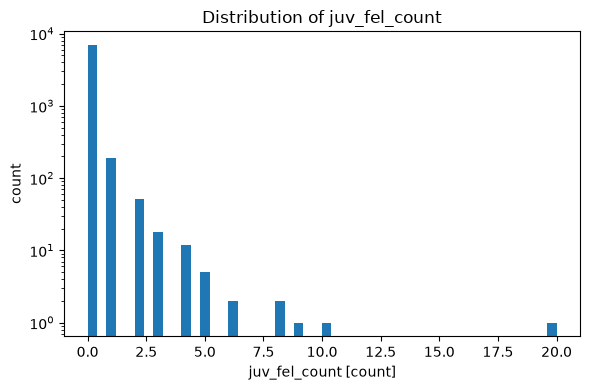

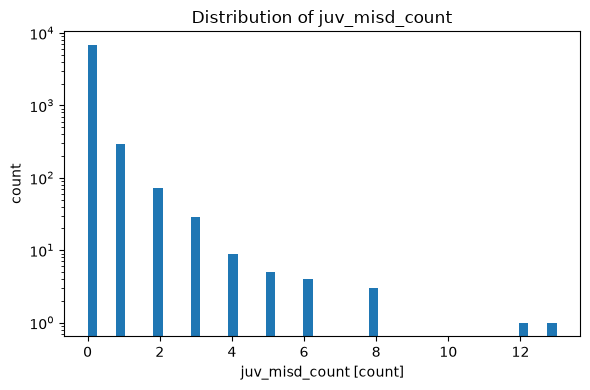

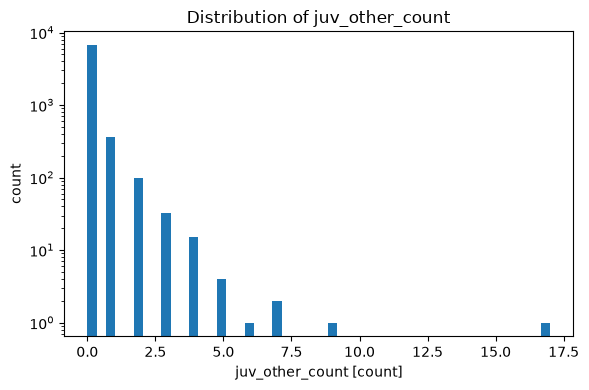

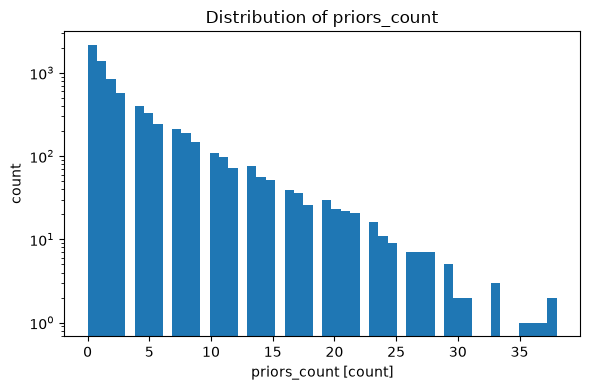

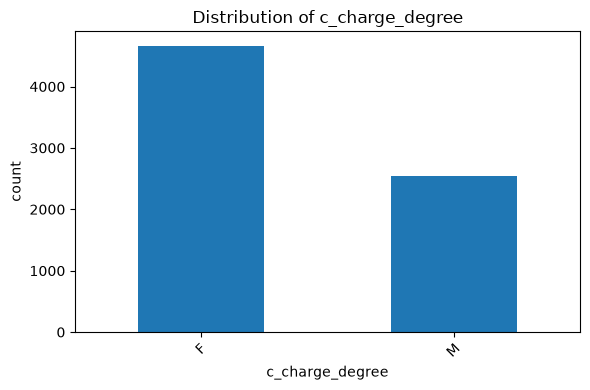

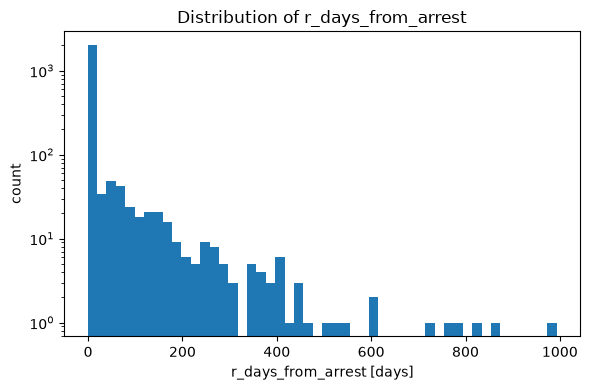

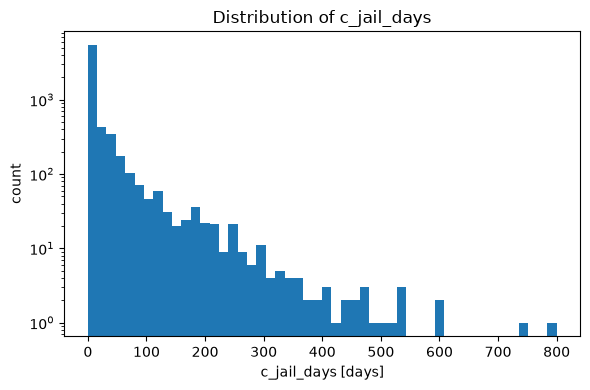

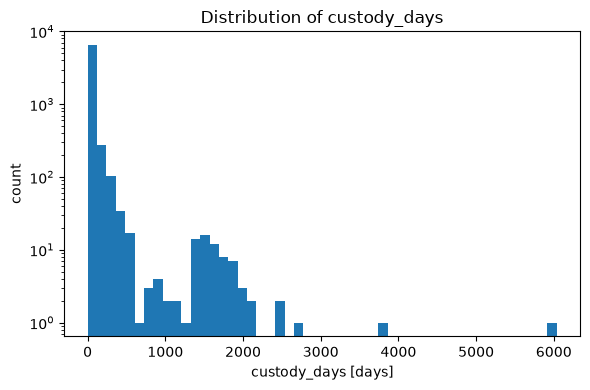

In [12]:
units = {'age': 'years', 'juv_fel_count': 'count', 'juv_misd_count': 'count',
         'juv_other_count': 'count', 'priors_count': 'count', 'r_days_from_arrest': 'days',
         'c_jail_days': 'days', 'custody_days': 'days'}

for col in X.columns:
    plt.figure(figsize=(6, 4))
    if col in units:
        X[col].plot.hist(bins=50, log=True)
        plt.xlabel(f'{col} [{units[col]}]')
    else:
        X[col].value_counts().plot.bar(rot=45)
        plt.xlabel(col)
    plt.ylabel('count')
    plt.title(f'Distribution of {col}')
    plt.tight_layout()
    plt.show()

**q1:** Use sklearn to split the dataset into 60% training, 20% validation, and 20% test sets.

In [13]:
X_train, X_other, y_train, y_other = train_test_split(X, y, train_size=0.6, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_other, y_other, train_size=0.5, random_state=42)
print(X_train.shape, X_val.shape, X_test.shape)

(4328, 12) (1443, 12) (1443, 12)


## Problem 2

You will preprocess the dataset in this problem. 

- First, you need to decide, based on the dataset description, which features are continuous, ordinal, and categorical.
- Then you will write functions that perform fit-transform on the training set. The functions you create are tested with sklearn. The ability to implement algorithms is a strong indicator that you understand them, and it is a crucial step in learning.
- Finally, you'll transform the validation and test sets using sklearn.

Follow the steps outlined below.

### Problem 2a (10 points)

Start by separating the features into continuous, ordinal, and categorical features. Each feature must appear **exactly once** across the three feature lists. For each ordinal feature, specify its categories from lowest to highest in `ordinal_cats`.

In [14]:
continuous_ftrs = ['age', 'juv_fel_count', 'juv_misd_count', 'juv_other_count', 'priors_count',
                   'r_days_from_arrest', 'c_jail_days', 'custody_days']
ordinal_ftrs = ['age_cat']
ordinal_cats = [['Less than 25', '25 - 45', 'Greater than 45']]
categorical_ftrs = ['sex', 'race', 'c_charge_degree']

Manually implement standard scaling in the `standard_scaler` function below, then test your implementation.

In [15]:
def standard_scaler(df,continuous_ftrs):
    '''
    Standardize continuous features by subtracting the mean and dividing by the standard deviation.
    Missing values are ignored when the mean and standard deviation are calculated and remain missing.

    Parameters:
    -----------
    df: a pandas dataframe that contains the features
    continuous_ftrs: a list of column names in df that are continuous

    Returns:
    --------
        a pandas dataframe containing only the scaled continuous features

    Example:
    --------
    >>> import pandas as pd
    >>>
    >>> df = pd.DataFrame({'a': [1, 2, 3], 'b': ['x', 'y', 'z']})
    >>>
    >>> df_scaled = standard_scaler(df, ['a'])

    '''
    if not isinstance(df, pd.DataFrame):
        raise ValueError('df must be a pandas dataframe, got ' + str(type(df)))
    if not isinstance(continuous_ftrs, list):
        raise ValueError('continuous_ftrs must be a list, got ' + str(type(continuous_ftrs)))
    missing = [c for c in continuous_ftrs if c not in df.columns]
    if missing:
        raise ValueError('columns not in df: ' + str(missing))
    non_numeric = [c for c in continuous_ftrs if not pd.api.types.is_numeric_dtype(df[c])]
    if non_numeric:
        raise ValueError('columns must be numeric: ' + str(non_numeric))

    df_cont = df[continuous_ftrs].astype(float)
    std = df_cont.std(ddof=0).replace(0, 1)
    df_scaled = (df_cont - df_cont.mean()) / std

    return df_scaled

In [16]:
df_scaled = standard_scaler(X_train, continuous_ftrs)
sk_scaled = StandardScaler().fit_transform(X_train[continuous_ftrs])

if not np.allclose(df_scaled.values, sk_scaled, equal_nan=True):
    raise ValueError('standard_scaler output does not match sklearn StandardScaler')
print('standard_scaler matches sklearn')

standard_scaler matches sklearn


### Problem 2b (10 points)

Manually implement one hot encoding in the `onehot_encoder` function below, then test your implementation.

In [17]:
def onehot_encoder(df,categorical_ftrs):
    '''
    One-hot encode categorical features. Each unique category of a feature becomes a new binary column
    named <feature>_<category>, with categories in sorted order.

    Parameters:
    -----------
    df: a pandas dataframe that contains the features
    categorical_ftrs: a list of column names in df that are categorical

    Returns:
    --------
        a pandas dataframe containing only the one-hot encoded features

    Example:
    --------
    >>> import pandas as pd
    >>>
    >>> df = pd.DataFrame({'a': ['x', 'y', 'x'], 'b': [1, 2, 3]})
    >>>
    >>> df_onehot = onehot_encoder(df, ['a'])

    '''
    if not isinstance(df, pd.DataFrame):
        raise ValueError('df must be a pandas dataframe, got ' + str(type(df)))
    if not isinstance(categorical_ftrs, list):
        raise ValueError('categorical_ftrs must be a list, got ' + str(type(categorical_ftrs)))
    missing = [c for c in categorical_ftrs if c not in df.columns]
    if missing:
        raise ValueError('columns not in df: ' + str(missing))

    cols = {}
    for ftr in categorical_ftrs:
        for cat in sorted(df[ftr].unique()):
            cols[f'{ftr}_{cat}'] = (df[ftr] == cat).astype(float)
    df_onehot = pd.DataFrame(cols, index=df.index)

    return df_onehot

In [18]:
df_onehot = onehot_encoder(X_train, categorical_ftrs)
ohe = OneHotEncoder(sparse_output=False)
sk_onehot = ohe.fit_transform(X_train[categorical_ftrs])

if list(df_onehot.columns) != list(ohe.get_feature_names_out()) or not np.array_equal(df_onehot.values, sk_onehot):
    raise ValueError('onehot_encoder output does not match sklearn OneHotEncoder')
print('onehot_encoder matches sklearn')

onehot_encoder matches sklearn


### Problem 2c (10 points)

Manually implement ordinal encoding in the `ordinal_encoder` function below, then test your implementation.

In [19]:
def ordinal_encoder(df, ordinal_ftrs, ordinal_cats):
    '''
    Ordinal encode features. Each category is replaced by its position in the ordered category list,
    so the lowest category becomes 0, the next 1, and so on. ordinal_ftrs and ordinal_cats are needed
    because the order of the categories cannot be inferred from the data, it has to be given explicitly.

    Parameters:
    -----------
    df: a pandas dataframe that contains the features
    ordinal_ftrs: a list of column names in df that are ordinal
    ordinal_cats: a list of lists, the i-th list contains the categories of ordinal_ftrs[i]
        ordered from lowest to highest

    Returns:
    --------
        a pandas dataframe containing only the ordinal encoded features

    Example:
    --------
    >>> import pandas as pd
    >>>
    >>> df = pd.DataFrame({'size': ['S', 'L', 'M']})
    >>>
    >>> df_ordinal = ordinal_encoder(df, ['size'], [['S', 'M', 'L']])

    '''
    if not isinstance(df, pd.DataFrame):
        raise ValueError('df must be a pandas dataframe, got ' + str(type(df)))
    if not isinstance(ordinal_ftrs, list) or not isinstance(ordinal_cats, list):
        raise ValueError('ordinal_ftrs and ordinal_cats must be lists')
    if len(ordinal_ftrs) != len(ordinal_cats):
        raise ValueError('ordinal_ftrs has ' + str(len(ordinal_ftrs)) + ' elements but ordinal_cats has '
                         + str(len(ordinal_cats)))
    missing = [c for c in ordinal_ftrs if c not in df.columns]
    if missing:
        raise ValueError('columns not in df: ' + str(missing))
    for ftr, cats in zip(ordinal_ftrs, ordinal_cats):
        unknown = set(df[ftr].unique()) - set(cats)
        if unknown:
            raise ValueError('unknown categories in ' + ftr + ': ' + str(unknown))

    df_ordinal = pd.DataFrame({ftr: df[ftr].map({cat: float(i) for i, cat in enumerate(cats)})
                               for ftr, cats in zip(ordinal_ftrs, ordinal_cats)}, index=df.index)

    return df_ordinal

In [20]:
df_ordinal = ordinal_encoder(X_train, ordinal_ftrs, ordinal_cats)
sk_ordinal = OrdinalEncoder(categories=ordinal_cats).fit_transform(X_train[ordinal_ftrs])

if not np.array_equal(df_ordinal.values, sk_ordinal):
    raise ValueError('ordinal_encoder output does not match sklearn OrdinalEncoder')
print('ordinal_encoder matches sklearn')

ordinal_encoder matches sklearn


### Problem 2d (5 points)

**q0:** Combine the transformed dataframes you created in 2a-c into one preprocessed X_train.

In [21]:
X_train_prep = pd.concat([df_scaled, df_onehot, df_ordinal], axis=1)
X_train_prep.head()

,age,juv_fel_count,juv_misd_count,juv_other_count,priors_count,r_days_from_arrest,c_jail_days,custody_days,sex_Female,sex_Male,race_African-American,race_Asian,race_Caucasian,race_Hispanic,race_Native American,race_Other,c_charge_degree_F,c_charge_degree_M,age_cat
218,2.186680,-0.140284,-0.182926,-0.227059,-0.511950,NaN,-0.347692,-0.236335,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,2.0
1962,1.347439,-0.140284,-0.182926,-0.227059,-0.511950,NaN,NaN,NaN,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,2.0
6530,0.340350,-0.140284,-0.182926,-0.227059,-0.710972,NaN,-0.019198,-0.148714,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
4695,-0.414967,-0.140284,-0.182926,-0.227059,-0.312927,NaN,NaN,NaN,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0
2213,0.843895,-0.140284,-0.182926,-0.227059,-0.511950,NaN,-0.243132,-0.210564,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,2.0


**q1:** Create an sklearn ColumnTransformer to preprocess the feature matrix.

In [22]:
preprocessor = ColumnTransformer(transformers=[
    ('std', StandardScaler(), continuous_ftrs),
    ('ohe', OneHotEncoder(sparse_output=False, handle_unknown='ignore'), categorical_ftrs),
    ('ord', OrdinalEncoder(categories=ordinal_cats), ordinal_ftrs)],
    verbose_feature_names_out=False).set_output(transform='pandas')

X_train_ct = preprocessor.fit_transform(X_train)

**q2:** Make sure that your combined dataframe (the preprocessed training set) is identical to the training set created by the sklearn column transformer. Create a test for this and fix any issues.

In [23]:
if list(X_train_prep.columns) != list(X_train_ct.columns) or not np.allclose(X_train_prep.values, X_train_ct.values, equal_nan=True):
    raise ValueError('manual preprocessing does not match the ColumnTransformer')
print('manual preprocessing matches the ColumnTransformer')

manual preprocessing matches the ColumnTransformer


**q3:** Transform the validation and test sets using the sklearn column transformer. Print out the heads of the train/val/test sets.

In [24]:
X_val_ct = preprocessor.transform(X_val)
X_test_ct = preprocessor.transform(X_test)

print(X_train_ct.head())
print(X_val_ct.head())
print(X_test_ct.head())

           age  juv_fel_count  juv_misd_count  juv_other_count  priors_count  \
218   2.186680      -0.140284       -0.182926        -0.227059     -0.511950   
1962  1.347439      -0.140284       -0.182926        -0.227059     -0.511950   
6530  0.340350      -0.140284       -0.182926        -0.227059     -0.710972   
4695 -0.414967      -0.140284       -0.182926        -0.227059     -0.312927   
2213  0.843895      -0.140284       -0.182926        -0.227059     -0.511950   

      r_days_from_arrest  c_jail_days  custody_days  sex_Female  sex_Male  \
218                  NaN    -0.347692     -0.236335         0.0       1.0   
1962                 NaN          NaN           NaN         1.0       0.0   
6530                 NaN    -0.019198     -0.148714         0.0       1.0   
4695                 NaN          NaN           NaN         0.0       1.0   
2213                 NaN    -0.243132     -0.210564         1.0       0.0   

      race_African-American  race_Asian  race_Caucasian 